# 02 · Análise de sobrevivência (A–H)

Mesma ordem do relatório HTML: **A** desenho · **B** ingênuo × Kaplan-Meier · **C** comparações · **D** Cox · **E** valor por canal · **F** o que poderia ter dado errado · **G** riscos competitivos (só depois de os testes passarem) · **H** limites. Para ser rápido, o bootstrap usa poucas réplicas aqui; `python run_all.py` usa o número completo.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
raiz = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(raiz / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from sobrevivencia import config as C, simulate as S, km as K, cohorts as H, cox as X
from sobrevivencia import value as V, pitfalls as P, competing as G, figures as F

pd.options.display.float_format = "{:,.3f}".format
pd.options.display.max_columns = 30
F._estilo()
df, lat = S.simular()
gt = S.construir_ground_truth(df, lat)
import tempfile
FIG = Path(tempfile.mkdtemp(prefix='figuras_nb_'))
print(f"{len(df):,} assinantes | seed {C.SEED} | corte {C.CORTE}")
N_BOOT = 200

12,000 assinantes | seed 42 | corte 2026-10-31


## A. Desenho

**Evento**: cancelamento efetivo. **Origem do tempo**: primeira cobrança. **Corte**: fixo em 31/10/2026. **Censura**: à direita.

In [2]:
pd.Series(H.resumo_dados(df)).to_frame('valor')

,valor
n,12000
n_eventos,3945
n_censurados,8055
pct_eventos,0.329
pct_censurados,0.671
entrada_ini,2024-11-01
entrada_fim,2026-10-31
corte,2026-10-31
seguimento_max_meses,23.984
seguimento_mediano_meses,11.203


## B. O erro clássico: retenção ingênua × Kaplan-Meier por safra

Só publicamos M12/M18/M24 onde **todos** os membros da safra tiveram tempo de ser observados (e há assinantes sob risco suficientes).

In [3]:
tab = H.tabela_safras(df)
linhas = []
for l in tab['safras']:
    r = {'safra': l['safra'], 'n': l['n'], 'ingenua': l['ret_ingenua']}
    for h in ('m3', 'm6', 'm12', 'm18', 'm24'):
        p = l['horizontes'][h]; r[f'KM {h}'] = p['valor'] if p['ok'] else np.nan
        if h in ('m12', 'm18', 'm24'): r[f'status {h}'] = p['status'] or '—'
    linhas.append(r)
pd.DataFrame(linhas).set_index('safra')

,n,ingenua,KM m3,KM m6,KM m12,status m12,KM m18,status m18,KM m24,status m24
safra,,,,,,,,,,
S1,1679,0.453,0.904,0.811,0.678,acima,0.522,abaixo,NaN,—
S2,1153,0.524,0.893,0.814,0.683,acima,0.543,indistinguivel,NaN,—
S3,1265,0.545,0.895,0.825,0.693,acima,NaN,—,NaN,—
S4,1199,0.601,0.881,0.807,0.674,indistinguivel,NaN,—,NaN,—
S5,2019,0.654,0.884,0.775,NaN,—,NaN,—,NaN,—
S6,1215,0.733,0.871,0.773,NaN,—,NaN,—,NaN,—
S7,1689,0.820,0.853,NaN,NaN,—,NaN,—,NaN,—
S8,1781,0.945,NaN,NaN,NaN,—,NaN,—,NaN,—


Spearman(ingênua, idade da safra) = -1.00  |  Spearman(KM M3, idade) = 0.93


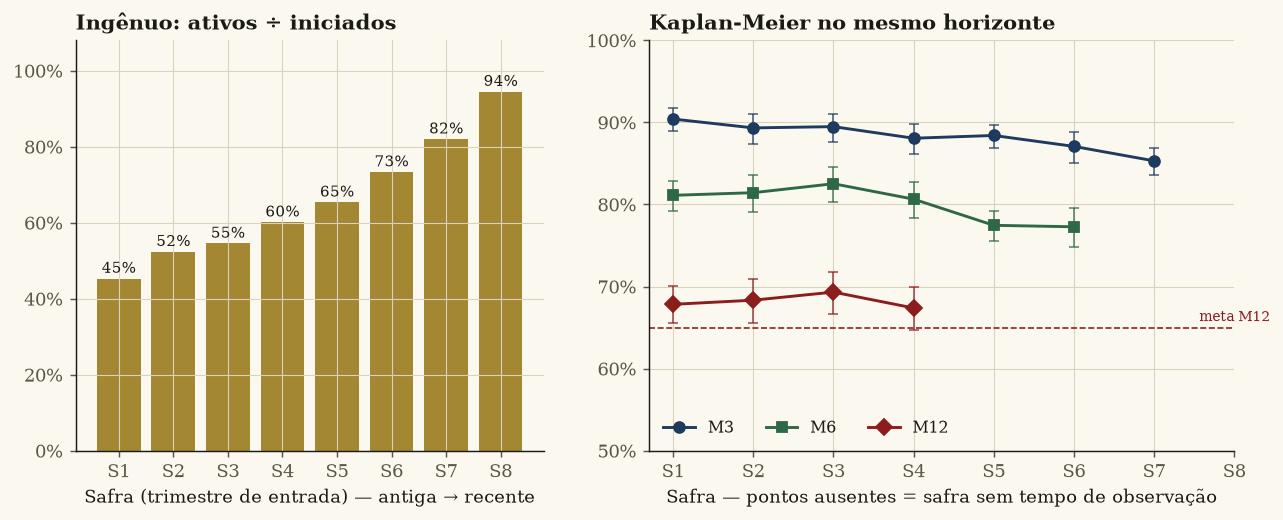

In [4]:
print(f"Spearman(ingênua, idade da safra) = {tab['rho_ingenua_idade']:.2f}  |  Spearman(KM M3, idade) = {tab['rho_km_m3_idade']:.2f}")
res_b = {'ingenuo_vs_km': tab}
display(Image(str(F.fig_ingenua_vs_km(res_b, FIG))))

## C. Comparações: log-rank e Holm

In [5]:
comp = H.comparacoes(df)
pd.DataFrame({k: v['logrank'] for k, v in comp.items()}).T

,chi2,df,p
canal,341.428,5.000,0.000
plano,285.948,3.000,0.000
safra,37.751,7.000,0.000


In [6]:
pares = pd.DataFrame(comp['canal']['pares'])[['rotulo_a', 'rotulo_b', 'chi2', 'p', 'p_holm', 'significativo_holm']]
pares

,rotulo_a,rotulo_b,chi2,p,p_holm,significativo_holm
0,Busca paga,E-mail/CRM,42.098,0.000,0.000,True
1,Busca paga,Indicação,65.883,0.000,0.000,True
2,Busca paga,Mídia paga (Meta),49.706,0.000,0.000,True
3,Busca paga,Orgânico,19.317,0.000,0.000,True
4,Busca paga,Social,12.717,0.000,0.001,True
5,E-mail/CRM,Indicação,8.081,0.004,0.009,True
6,E-mail/CRM,Mídia paga (Meta),159.702,0.000,0.000,True
7,E-mail/CRM,Orgânico,10.050,0.002,0.005,True
8,E-mail/CRM,Social,84.192,0.000,0.000,True
9,Indicação,Mídia paga (Meta),165.158,0.000,0.000,True


{'canal': (15, 15, 15), 'plano': (6, 6, 6), 'safra': (12, 5, 28)} (bruto, Holm, pares)


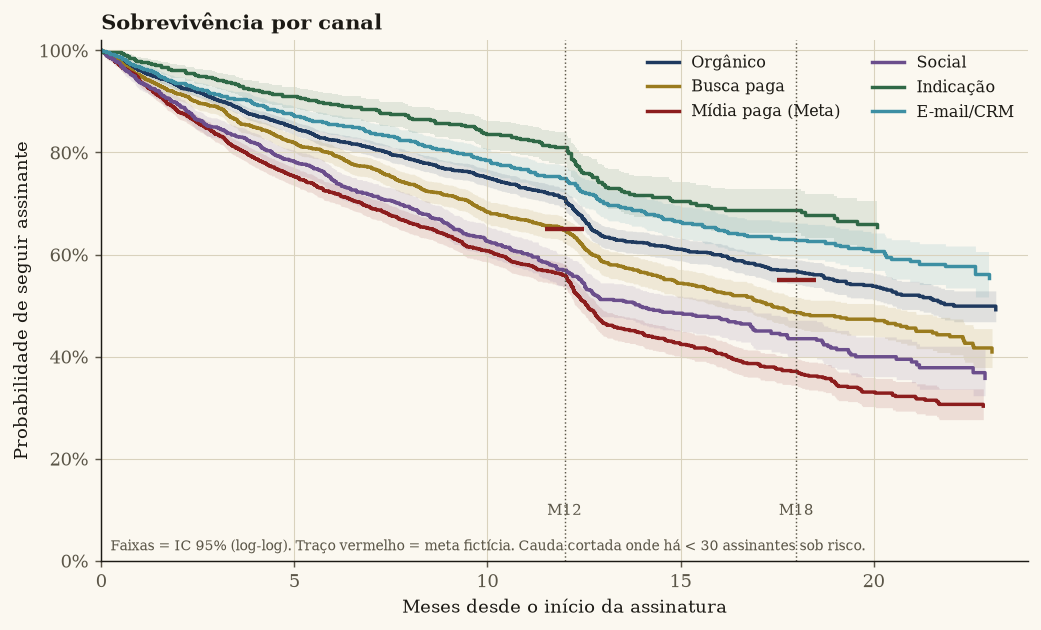

In [7]:
print({k: (v['n_sig_bruto'], v['n_sig_holm'], v['n_pares']) for k, v in comp.items()}, '(bruto, Holm, pares)')
display(Image(str(F.fig_km_grupos(df, 'canal', C.CANAIS, C.CANAIS_ROTULO, C.COR_CANAL, 'Sobrevivência por canal', FIG, 'km_canal.png'))))

## D. Cox: mostrar a violação, corrigir e comparar com o plantado

In [8]:
cph_i, d_i = X.ajustar_ingenuo(df)
covs_i = [c for c in d_i.columns if c not in ('duracao', 'evento')]
ph_i = X.teste_ph(d_i, covs_i, cph_i.params_[covs_i].to_numpy(), stop='duracao', evento='evento')
tab_i = pd.DataFrame(X.tabela_hr(cph_i)).set_index('nome')[['hr', 'lo', 'hi', 'verdade']]
tab_i.join(pd.DataFrame(X.resumo_ph(ph_i, covs_i)).set_index('nome')[['p_rank', 'p_faixas', 'viola']])

,hr,lo,hi,verdade,p_rank,p_faixas,viola
nome,,,,,,,
canal_busca_paga,1.176,1.068,1.295,1.150,0.974,0.253,False
canal_midia_paga,1.476,1.350,1.613,1.500,0.585,0.539,False
canal_social,1.338,1.204,1.486,1.200,0.412,0.018,False
canal_indicacao,0.708,0.603,0.832,0.700,0.288,0.722,False
canal_email_crm,0.898,0.796,1.013,0.850,0.699,0.708,False
plano_anual,0.453,0.405,0.506,NaN,0.000,0.000,True
plano_combo,0.780,0.717,0.849,0.750,0.004,0.001,True
plano_estudante,1.111,1.025,1.205,1.200,0.004,0.000,True
disp_desktop,1.031,0.963,1.105,1.000,0.391,0.505,False


In [9]:
print('Teste global de Schoenfeld (ingênuo):', ph_i['global_rank'])
print('C-index (ingênuo):', round(cph_i.concordance_index_, 3))
print('Efeito local da promoção por faixa de idade:', [(x['ini'], round(x['hr_local'], 2)) for x in ph_i['efeito_local']['oferta_bf']])

Teste global de Schoenfeld (ingênuo): {'chi2': 326.3728025396432, 'df': 13, 'p': 7.15127806418701e-62}
C-index (ingênuo): 0.652
Efeito local da promoção por faixa de idade: [(0.0, 0.9), (3.0, 3.68), (4.0, 1.48), (6.0, 1.06), (12.0, 1.21)]


In [10]:
ep = X.episodios(df)
cph_c, d_c = X.ajustar_corrigido(ep)
covs_c = X.COVS_CORRIGIDO
ph_c = X.teste_ph(d_c, covs_c, cph_c.params_[covs_c].to_numpy(), stop='stop', evento='evento', start='start', strata='plano')
print('Episódios:', len(ep), '| Teste global (corrigido):', ph_c['global_rank'])
pd.DataFrame(X.tabela_hr(cph_c)).set_index('nome')[['hr', 'lo', 'hi', 'verdade', 'cobre', 'erro_rel']]

Episódios: 23632 | Teste global (corrigido): {'chi2': 5.9065306819032335, 'df': 13, 'p': 0.9494885840749164}


,hr,lo,hi,verdade,cobre,erro_rel
nome,,,,,,
canal_busca_paga,1.174,1.066,1.292,1.150,True,0.021
canal_midia_paga,1.485,1.359,1.624,1.500,True,-0.010
canal_social,1.328,1.195,1.475,1.200,True,0.106
canal_indicacao,0.715,0.609,0.840,0.700,True,0.022
canal_email_crm,0.901,0.799,1.016,0.850,True,0.060
disp_desktop,1.032,0.964,1.106,1.000,True,0.032
disp_tablet,1.018,0.905,1.145,1.000,True,0.018
eng_z,0.795,0.770,0.821,0.780,True,0.019
oferta_copa,1.478,1.219,1.793,1.600,True,-0.076


In [11]:
cph_p, _ = X.ajustar_complementar(df, ep)
print('HR de plano (modelo sem o anual):')
pd.DataFrame([r for r in X.tabela_hr(cph_p) if r['nome'].startswith('plano')]).set_index('nome')[['hr', 'lo', 'hi', 'verdade', 'cobre']]

HR de plano (modelo sem o anual):


,hr,lo,hi,verdade,cobre
nome,,,,,
plano_combo,0.785,0.721,0.855,0.750,True
plano_estudante,1.189,1.094,1.291,1.200,True


## E. Valor por canal: RMST, LTV descontado, CAC e payback

ARPU, CAC e taxa de desconto são **premissas** (`config.py`). Medido = coberto pelo KM; projetado = cauda extrapolada.

In [12]:
valor = V.analise_valor(df, n_boot=N_BOOT)
pd.DataFrame([{'canal': c['rotulo'], 'CAC': c['cac'], 'RMST_24m': c['rmst']['est'], 'LTV_24m': c['ltv']['est'],
               'LTV_lo': c['ltv']['lo'], 'LTV_hi': c['ltv']['hi'], '% medido': c['pct_ltv_medido'],
               'LTV/CAC': c['ltv_cac']['est'], 'payback (mens.)': c['payback']['est']} for c in valor['canais']]).set_index('canal')

,CAC,RMST_24m,LTV_24m,LTV_lo,LTV_hi,% medido,LTV/CAC,payback (mens.)
canal,,,,,,,,
Orgânico,30.000,16.854,454.446,444.723,464.183,1.000,15.148,2.000
Busca paga,95.000,15.610,422.545,411.369,433.835,1.000,4.448,4.000
Mídia paga (Meta),52.000,13.401,368.570,356.021,380.161,1.000,7.088,2.000
Social,60.000,14.365,376.668,360.931,391.864,0.978,6.278,3.000
Indicação,56.000,19.029,497.892,479.535,518.702,1.000,8.891,3.000
E-mail/CRM,22.000,17.900,494.050,479.367,507.389,1.000,22.457,1.000


In [13]:
print('Ranking só por CAC (canais com verba):      ', valor['ranking_cac'])
print('Ranking por LTV/CAC (com permanência):       ', valor['ranking_ltv_cac'])
dec = V.decisao_verba(valor)
print(f"Realocar R$ {dec['verba_exemplo']:,.0f} do pior para o melhor: +R$ {dec['ganho_realocar_pior_para_melhor']:,.0f} de valor líquido (PROJETADO)")
acao = V.acao_mes3(df, X.tabela_hr(cph_c))
print('MEDIDO  -> prob. de cancelar no mês 3-4 (Black Friday):', round(acao['medido']['q_penhasco'], 3))
p = acao['projetado']
print(f"PROJETADO -> ação de R$ {p['custo_por_assinante']:.0f}/assinante: líquido R$ {p['base']['liquido']:,.0f} com efetividade {p['efetividade_base']:.0%}; "
      f"equilíbrio em {p['efetividade_equilibrio']:.0%}")

Ranking só por CAC (canais com verba):       ['midia_paga', 'indicacao', 'social', 'busca_paga']
Ranking por LTV/CAC (com permanência):        ['indicacao', 'midia_paga', 'social', 'busca_paga']
Realocar R$ 100,000 do pior para o melhor: +R$ 444,308 de valor líquido (PROJETADO)
MEDIDO  -> prob. de cancelar no mês 3-4 (Black Friday): 0.103
PROJETADO -> ação de R$ 4/assinante: líquido R$ 2,565 com efetividade 35%; equilíbrio em 16%


## F. O que poderia ter dado errado

In [14]:
pd.DataFrame(P.censura_ignorada(df, gt)['metodos'])[['rotulo', 'valor', 'erro_pp']]

,rotulo,valor,erro_pp
0,Ativos hoje ÷ iniciados (ignora o tempo de casa),0.671,0.017
1,Tratar censurado como cancelado,0.301,-0.353
2,Descartar quem foi censurado antes de M12,0.537,-0.117
3,Kaplan-Meier (usa a censura corretamente),0.661,0.007


In [15]:
bf = next(r for r in X.resumo_ph(ph_i, covs_i) if r['nome'] == 'oferta_bf')
pv = P.ph_violada(df, float(np.exp(cph_i.params_['oferta_bf'])), X.tabela_hr(cph_c), bf['p_faixas'], bf['p_rank'])
print({k: round(v, 4) for k, v in pv.items() if isinstance(v, float)})

{'hr_unico_ingenuo': 1.1962, 'p_rank_ingenuo': 0.1454, 'p_faixas_ingenuo': 0.0, 'q_base_mes3': 0.0363, 'q_observado_bf_mes3': 0.1035, 'q_previsto_ingenuo': 0.0433, 'q_previsto_corrigido': 0.1002, 'subestimacao_ingenua': 1.3921}


In [16]:
rk = P.ranking_m12_bruto(df, gt)
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in rk.items() if k != 'safras_reais'})

{'tamanho_safra_pequena': 300, 'n_sorteios': 1000, 'n_elegiveis': 5296, 'melhor_verdadeiro': 'indicacao', 'pior_verdadeiro': 'midia_paga', 'p_acerta_melhor': 0.655, 'p_acerta_pior': 0.513, 'erro_abs_medio_pp': 0.059, 'largura_media_ic': 0.26, 'n_mediano_menor_canal': 23.0}


## G. Riscos competitivos (Aalen-Johansen)

Seção feita **depois** que os testes das etapas anteriores passaram (`python run_all.py` aplica essa trava antes de calcular a seção G).

In [17]:
rc = G.analise(df, gt, n_boot=100)
pd.DataFrame({m: {k: v['est'] for k, v in pts.items() if isinstance(v, dict)} for m, pts in rc['pontos'].items()})

,m6,m12,m18
voluntario,0.165,0.285,0.369
involuntario,0.038,0.054,0.071
fim_contrato,0.000,0.000,0.050


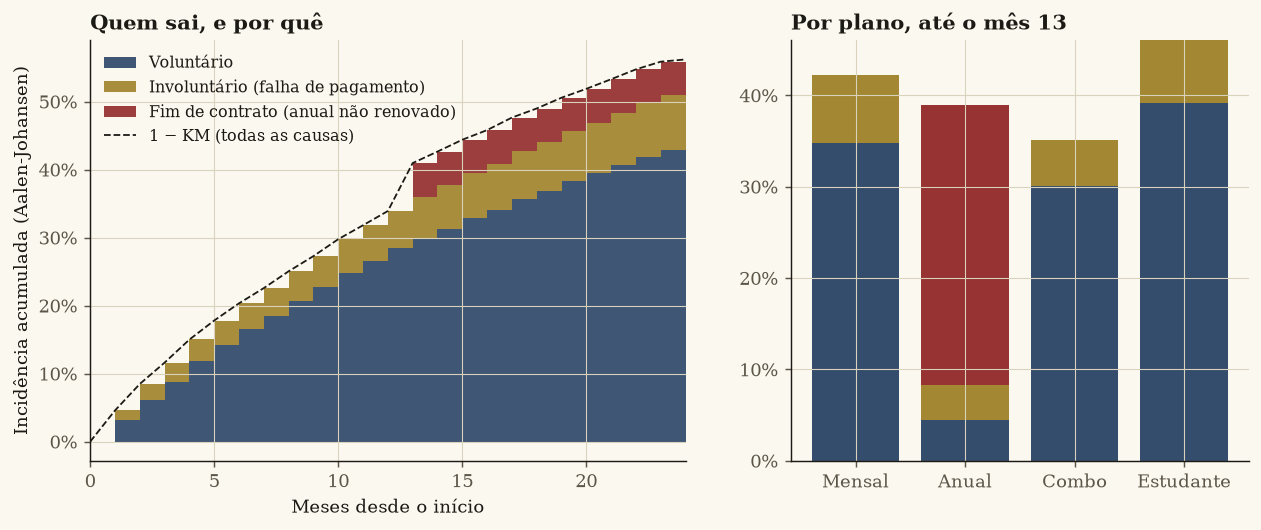

In [18]:
res_g = {'riscos_competitivos': rc}
display(Image(str(F.fig_riscos_competitivos(res_g, FIG))))

## H. Limites honestos

- Dados sintéticos e efeitos plantados: o notebook mostra que o método recupera o efeito certo, não uma descoberta sobre o mundo.
- M24 não é observável com esta janela.
- ARPU, CAC, taxa de desconto e a efetividade da ação do mês 3 são premissas.
- O KM agregado mistura safras com riscos diferentes; o reajuste de preço é associação, não causalidade.